In [1]:
import pandas as pd
metadata_path = r"C:\Users\papan\Desktop\Coffeomics\sample_information.csv"
metadata = pd.read_csv(metadata_path, index_col=0)
metadata = metadata[metadata.Transcriptomics == True].T
metadata

Sample_ID,7A,7B,7C,20B,20C,8A,9B,9C,9E,10A,...,49C,51A,51B,51C,52A,52C,52D,54B,54C,54D
Species,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,C. arabica,...,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora,C. canephora
Temperature,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,25/20°C,...,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C,Rec 14 - 25/20°C
CO2_ppm,380ppm,380ppm,380ppm,380ppm,380ppm,380ppm,380ppm,380ppm,380ppm,700ppm,...,380ppm,380ppm,380ppm,380ppm,700ppm,700ppm,700ppm,700ppm,700ppm,700ppm
Water_Stress,without,without,without,medium,medium,medium,severe,severe,severe,without,...,without,severe,severe,severe,without,without,without,severe,severe,severe
Transcriptomics,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
Proteomic,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
Metabolomics,False,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


In [2]:
type_ = "Transcriptomics"

path = r"C:\Users\papan\Desktop\Coffeomics\Coffeeomics.xlsx"

trans_raw_data = pd.read_excel(
    path,
    sheet_name="Trans_Counts",
    index_col=0,
    header=4
)

trans_raw_data = trans_raw_data.loc[:, metadata.columns]
trans_raw_data.head()

Sample_ID,7A,7B,7C,20B,20C,8A,9B,9C,9E,10A,...,49C,51A,51B,51C,52A,52C,52D,54B,54C,54D
GSCOC_T00012439001,3,6,4,7,14,5,5,1,5,12,...,5,5,0,4,10,1,5,0,5,2
GSCOC_T00012438001,66,151,79,115,133,124,155,87,136,143,...,94,23,32,116,21,18,18,6,48,23
GSCOC_T00012437001,737,2078,1060,1704,1756,1955,2511,1117,1286,2011,...,1996,467,513,2942,299,286,308,191,857,313
GSCOC_T00012436001,31,6412,32,25,20,25,108,13,68,18,...,561,110,153,10127,29,26,43,12,112,48
GSCOC_T00012435001,2946,11,316,139,43,93,12,26,6,393,...,1798,296,517,2403,291,407,512,37,455,383


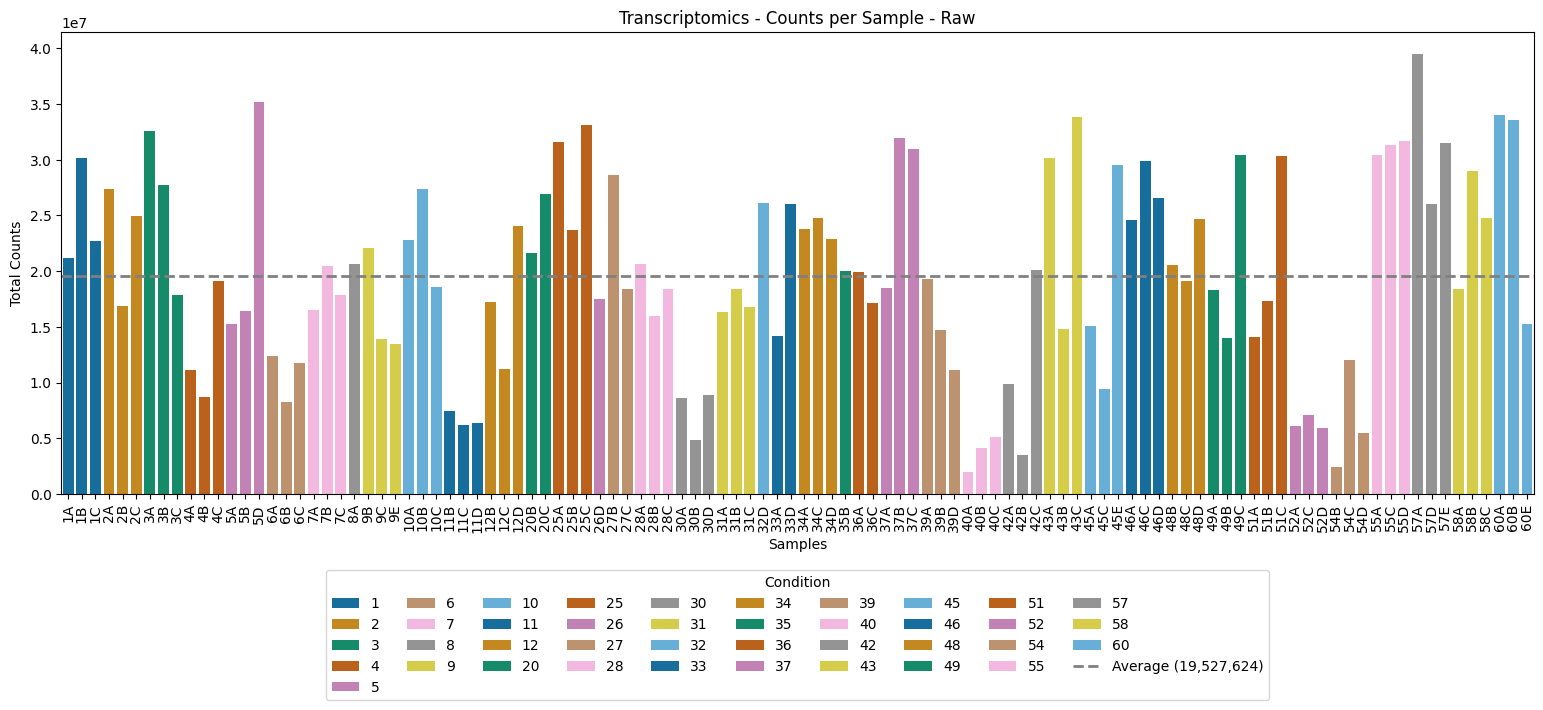

In [3]:
from data_characterization import to_bar_graph_counts_per_sample
to_bar_graph_counts_per_sample(trans_raw_data, f"{type_} - Counts per Sample - Raw",True, True)


Fitting size factors...
... done in 0.14 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 6.15 seconds.

Fitting dispersion trend curve...
... done in 0.84 seconds.

Fitting MAP dispersions...
... done in 7.71 seconds.

Fitting LFCs...
... done in 8.05 seconds.

Calculating cook's distance...
... done in 0.26 seconds.

Replacing 0 outlier genes.



AnnData object with n_obs × n_vars = 108 × 21971
    obs: 'condition', 'size_factors', 'replaceable'
    var: '_normed_means', 'non_zero', '_MoM_dispersions', 'genewise_dispersions', '_genewise_converged', 'fitted_dispersions', 'MAP_dispersions', '_MAP_converged', 'dispersions', '_outlier_genes', '_LFC_converged', 'replaced', 'refitted', '_pvalue_cooks_outlier'
    uns: 'trend_coeffs', 'disp_function_type', '_squared_logres', 'prior_disp_var'
    obsm: 'design_matrix', '_mu_LFC', '_hat_diagonals'
    varm: 'LFC'
    layers: 'normed_counts', '_mu_hat', 'cooks'


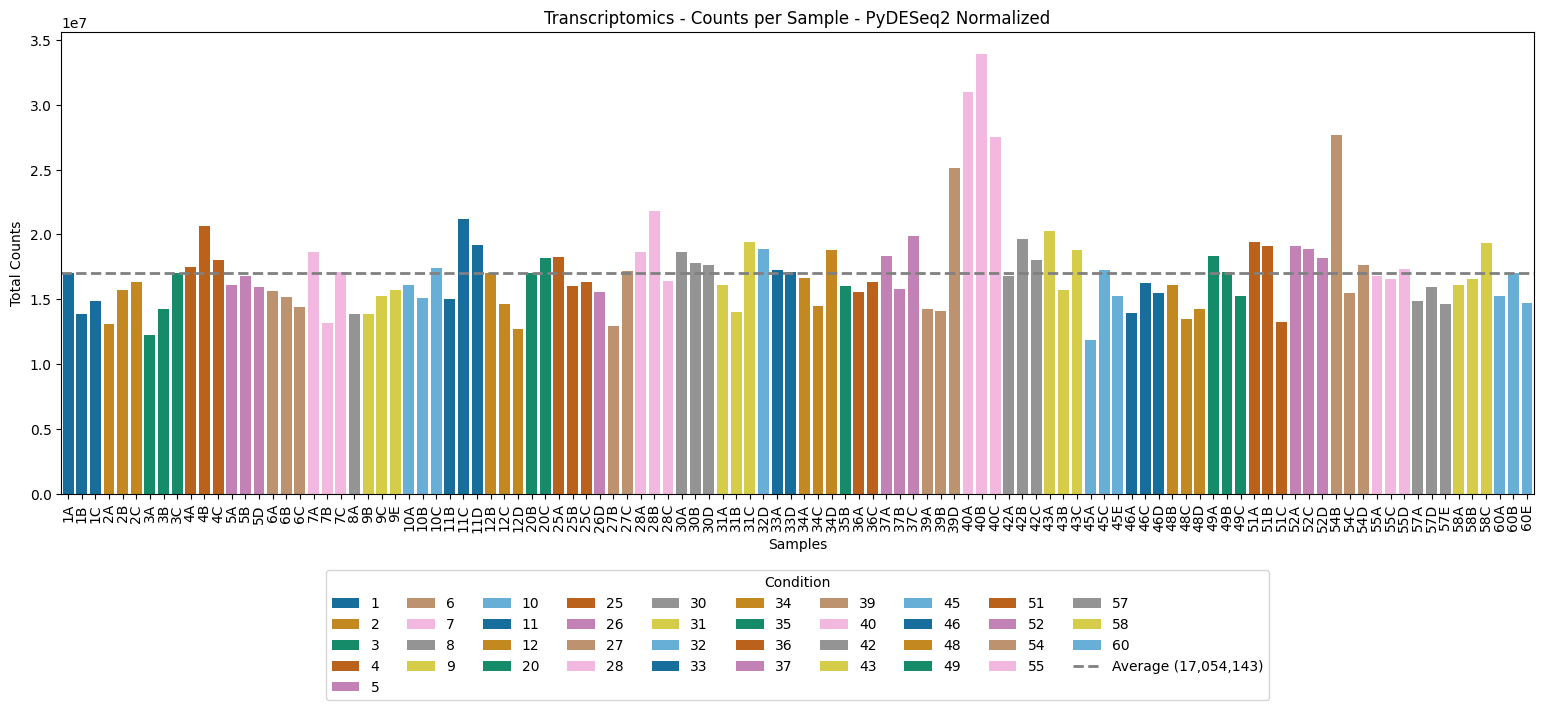

In [33]:
from data_normalization import pydeseq2_normalization 
pydeseq2_normalized = pydeseq2_normalization(trans_raw_data,"trans_counts_pydeseq2_normalized")
to_bar_graph_counts_per_sample(pydeseq2_normalized, f"{type} - Counts per Sample - PyDESeq2 Normalized",True, True)

In [34]:
pydeseq2_normalized.to_csv("trans_pydeseq2_normalized_counts.csv")

In [4]:
import pandas as pd
pydeseq2_normalized = pd.read_csv(r"C:\Users\papan\Desktop\Coffeomics\trans_normalizations\trans_pydeseq2_normalized_counts.csv", index_col=0)
table_1 = to_table_counts_per_sample(pydeseq2_normalized, "PyDESeq2")
display (table_1)

,Sample,PyDESeq2
0,7A,1.854891e+07
1,7B,1.310386e+07
2,7C,1.703126e+07
3,8A,1.377729e+07
4,9B,1.379266e+07
...,...,...
102,52D,1.810932e+07
103,54B,2.749009e+07
104,54C,1.535046e+07
105,54D,1.751691e+07


In [24]:
df_merged = pd.merge(table, table_1, on="Sample")
df_merged = df_merged.set_index("Sample")
df_merged["|PyDESeq2 - Raw Data|"] = (df_merged["PyDESeq2"] - df_merged["Raw Data"]).abs()
df_merged = df_merged.drop("40A")
df_merged = df_merged.drop("TOTAL")
df_merged = df_merged.drop(columns="PyDESeq2")
display(df_merged)
display(df_merged.nlargest(15, "|PyDESeq2 - Raw Data|"))

,Raw Data,|PyDESeq2 - Raw Data|
Sample,,
7A,16553848,1.995059e+06
7B,20461174,7.357318e+06
7C,17827042,7.957814e+05
8A,20627191,6.849904e+06
9B,22052188,8.259528e+06
...,...,...
52C,7044731,1.174952e+07
52D,5881506,1.222782e+07
54B,2407232,2.508286e+07


,Raw Data,|PyDESeq2 - Raw Data|
Sample,,
40B,4095450,2.964103e+07
54B,2407232,2.508286e+07
57A,39500841,2.472295e+07
40C,5112320,2.224449e+07
3A,32572989,2.037270e+07
5D,35142817,1.929714e+07
60A,34014035,1.884622e+07
51C,30348031,1.717334e+07
57E,31511765,1.698535e+07


In [25]:
samples_1 = df_merged.nlargest(15, "|PyDESeq2 - Raw Data|").index

1. Desenvolvimento nova estratégia de normalização

1.1 MAD Approach

In [ ]:
from data_normalization import our_normalization, our_normalization_factors, distribution_cohesion
results = []
data = trans_raw_data.drop(columns=['54B'])
for bins in range(50, 301, 10):
    for window in [1, 3, 5, 7]: #, 5, 7
        normalization = our_normalization (data, nbins=bins, window=window)
        to_bar_graph_counts_per_sample (normalization, f"{type} - Counts per Sample - Peaks Determined by Rolling Average of {window} Normalized Considering {bins} Bins",True, True)
        peaks = our_normalization_factors (data, nbins=bins, window=window, show=False, single_figure=False)
        mad = distribution_cohesion(peaks)
        results.append((bins, window, mad))

top5 = sorted(results, key=lambda x: x[2])[:5]
print("\nTop 5 parameter combinations:")
for i, (bins, window, mad) in enumerate(top5, start=1):
    print(f"{i}. Bins={bins}, Window={window}, MAD={mad:.4f}")

In [6]:
import os
import matplotlib.pyplot as plt
from data_normalization import our_normalization

base_dir = r"C:\Users\papan\Desktop\Coffeomics\trans_normalizations\Total Counts Distribution"
os.makedirs(base_dir, exist_ok=True)

params = [
    (5, 150),
    (3, 140),
    (5, 70),
    (5, 300),
    (7, 150)
]

for window, nbins in params:
    normalization = our_normalization(trans_raw_data, nbins=nbins, window=window)

    original_show = plt.show
    plt.show = lambda *args, **kwargs: None

    to_bar_graph_counts_per_sample(
        normalization,
        f"{type} - Counts per Sample - Peaks Determined by Rolling Average of {window} Normalized Considering {nbins} Bins",
        True,
        True
    )

    plt.show = original_show

    fig = plt.gcf()
    filename = f"window={window}_bins={nbins}.png"
    fig.savefig(os.path.join(base_dir, filename), bbox_inches="tight", dpi=150)
    plt.close(fig)


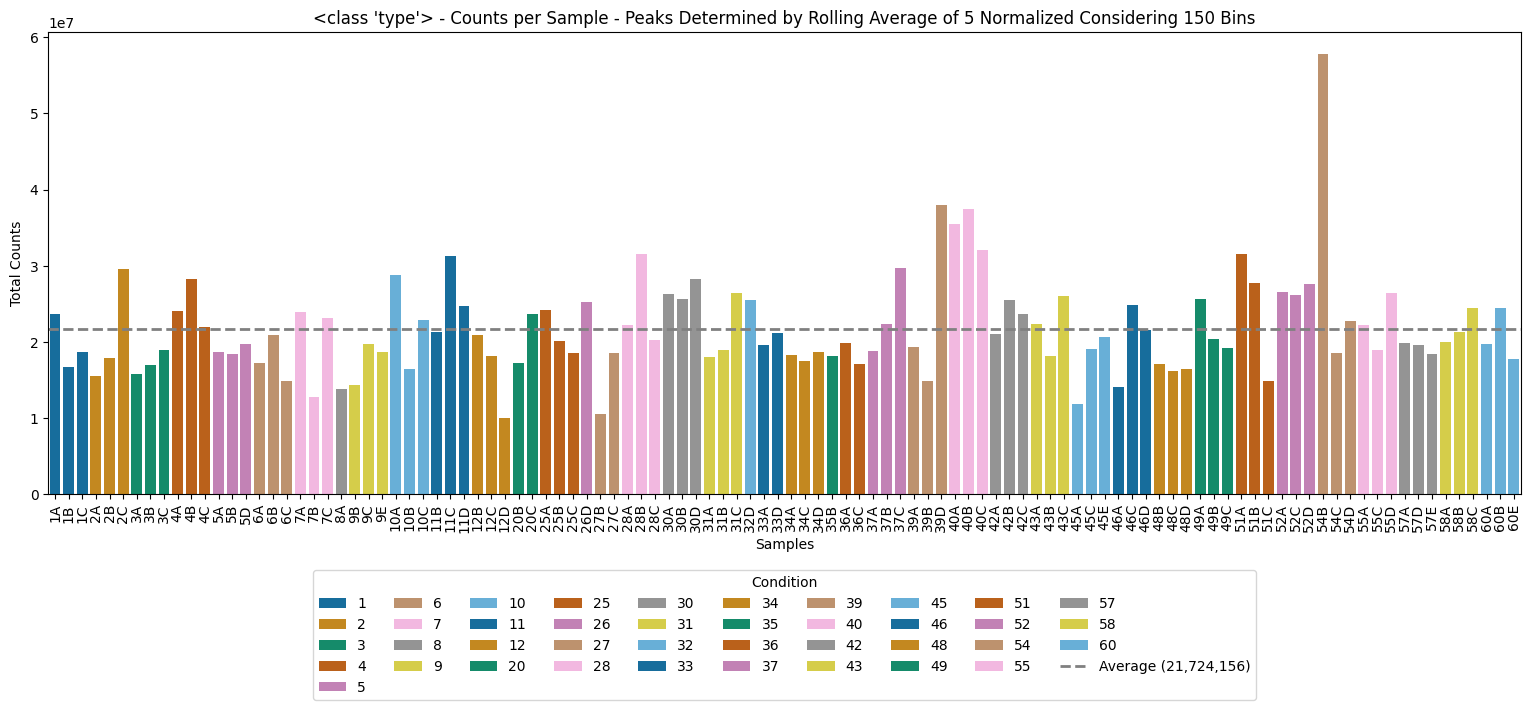

In [7]:
from data_normalization import our_normalization
from data_characterization import to_bar_graph_counts_per_sample

window = 5
bins   = 150
normalization = our_normalization(trans_raw_data, nbins=bins, window=window)
to_bar_graph_counts_per_sample(
    normalization,
    f"{type} - Counts per Sample - Peaks Determined by Rolling Average of {window} Normalized Considering {bins} Bins",
    True,
    True
)
output_path = f"C:\\Users\\papan\\Desktop\\Coffeomics\\transcriptomics\\trans_normalizations\\trans_{bins}bins_window{window}_normalized_counts.csv"
normalization.to_csv(output_path)

In [57]:
import pandas as pd
data = pd.read_csv(r"trans_normalizations\trans_150bins_window7_normalized_counts.csv", index_col=0)
column_name = "Bins=150, Window=7"
df_merged = pd.merge(table, to_table_counts_per_sample(data, column_name), on="Sample")
df_merged = df_merged.set_index("Sample")
df_merged[f"|{column_name} - Raw Data|"] = (df_merged[f"{column_name}"] - df_merged["Raw Data"]).abs()
df_merged = df_merged.drop("40A")
df_merged = df_merged.drop("TOTAL")
df_merged = df_merged.drop(columns=[f"{column_name}","Raw Data"])
display(df_merged.nlargest(15, f"|{column_name} - Raw Data|"))

,"|Bins=150, Window=7 - Raw Data|"
Sample,
54B,3.797187e+07
40B,3.444999e+07
40C,2.786535e+07
39D,2.502019e+07
52C,2.186432e+07
11C,2.136955e+07
52A,2.120427e+07
42B,1.896127e+07
52D,1.844854e+07


In [58]:
samples_2 = df_merged.nlargest(15, f"|{column_name} - Raw Data|").index
samples_combined = pd.Series(samples_1.union(samples_2), name="Sample")
samples_combined = samples_combined.iloc[
    samples_combined.str.extract(r"(\d+)")[0].astype(int).argsort().values
].reset_index(drop=True)
print(samples_combined)

0      1B
1      3A
2      5D
3     11C
4     25C
5     27B
6     30B
7     30A
8     37B
9     39D
10    40C
11    40B
12    42B
13    51A
14    51C
15    52A
16    52C
17    52D
18    54B
19    57A
20    57E
21    60A
22    60B
Name: Sample, dtype: object


In [59]:
from data_normalization import gene_distribution, our_normalization_factors

df_ref_samples = pd.DataFrame()
df_ref_samples["Samples"] = samples_combined.values

from itertools import product

windows = [1, 3, 5, 7]
nbins_list = list(range(50, 310, 10))

params = list(product(windows, nbins_list))

for window, nbins in params:
    peaks = our_normalization_factors(trans_raw_data, nbins=nbins, window=window, show=False, single_figure=False)
    df_ref_samples[f"Bins={nbins},Window={window}"] = [peaks[s] for s in df_ref_samples["Samples"]]

display(df_ref_samples)
df_ref_samples.to_excel("ref_samples_normalization_peaks_parsing.xlsx", index=False)

C:\Users\papan\AppData\Local\Temp\ipykernel_42684\1265277000.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_ref_samples[f"Bins={nbins},Window={window}"] = [peaks[s] for s in df_ref_samples["Samples"]]
C:\Users\papan\AppData\Local\Temp\ipykernel_42684\1265277000.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_ref_samples[f"Bins={nbins},Window={window}"] = [peaks[s] for s in df_ref_samples["Samples"]]
C:\Users\papan\AppData\Local\Temp\ipykernel_42684\1265277000.py:15: PerformanceWarning: DataFrame is highly fragme

,Samples,"Bins=50,Window=1","Bins=60,Window=1","Bins=70,Window=1","Bins=80,Window=1","Bins=90,Window=1","Bins=100,Window=1","Bins=110,Window=1","Bins=120,Window=1","Bins=130,Window=1",...,"Bins=210,Window=7","Bins=220,Window=7","Bins=230,Window=7","Bins=240,Window=7","Bins=250,Window=7","Bins=260,Window=7","Bins=270,Window=7","Bins=280,Window=7","Bins=290,Window=7","Bins=300,Window=7"
0,1B,1148.188531,1086.574635,1044.599512,1164.130359,1120.384628,1086.574635,1059.672206,1137.682115,1109.870995,...,940.424281,934.827433,1181.709581,1164.130359,1148.188531,1133.666833,991.144159,1199.040695,1139.486683,1127.271838
1,3A,1214.828873,1111.508975,1414.784157,1483.781327,1079.060007,1764.590992,1474.816330,1517.121749,1119.134717,...,1278.125402,1306.467671,1272.492841,1483.781327,1323.040539,1461.129682,1167.773464,1336.209429,1170.959325,1425.604121
2,5D,1125.884139,752.256917,783.856103,1245.304561,728.563116,752.256917,1607.502891,716.997558,735.772919,...,828.062689,835.321876,1137.220540,1131.301993,815.439401,821.969594,1116.316383,800.150021,945.314580,781.708799
3,11C,145.680490,137.439023,111.630756,110.475902,124.726241,154.416153,108.304252,144.273368,107.425717,...,124.726241,123.630554,135.710029,127.789712,126.678290,143.735794,130.224338,152.501163,150.437197,148.536039
4,25C,1218.612338,1152.421415,1107.354960,1074.715485,1049.995816,1030.630091,1123.535141,1100.017120,834.993222,...,1369.884656,1275.586628,1195.168972,1179.552452,1165.365536,1152.421415,1140.564348,1129.663476,1163.571533,1196.136714
5,27B,1722.898749,1471.644204,1527.925200,1571.544003,1606.328826,1634.710223,1507.214580,1537.512441,1563.624308,...,1527.925200,1543.644710,1707.226872,1571.544003,1518.777696,1595.544580,1670.080476,1556.867771,1625.848950,1634.710223
6,30B,110.333018,108.250537,125.733607,140.675143,135.200053,116.823932,115.016727,137.364043,112.290849,...,125.733607,124.341207,123.083356,121.941508,126.557728,119.947202,119.071345,123.192660,122.242342,116.823932
7,30A,258.270103,181.084856,227.209190,176.904109,239.669440,174.442136,182.629502,172.819884,179.788056,...,204.198411,207.445011,200.441385,203.518168,197.338957,227.910110,194.734051,241.274268,178.191147,244.190087
8,37B,1049.195462,993.935204,956.254631,928.934645,908.226542,993.935204,969.788465,1039.776542,1014.836065,...,862.610673,900.811323,894.093792,887.980070,921.425890,877.265716,984.025903,974.912890,931.103629,958.721617
9,39D,172.477133,189.651337,172.477133,185.203765,195.748016,182.585445,191.294983,180.860495,188.271595,...,182.090930,177.000518,181.234093,168.432319,180.517466,176.296968,195.748016,183.329736,201.820365,175.782809


In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import os

df = pd.read_excel("ref_samples_normalization_peaks_parsing.xlsx")

output_dir = r"C:\Users\papan\Desktop\Coffeomics\trans_normalizations\Peak Distributions"
os.makedirs(output_dir, exist_ok=True)

for idx, row in df.iterrows():
    sample = row["Samples"]
    values = row.drop("Samples")

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.scatter(range(len(values)), values, edgecolor='black', alpha=0.7)

    # Red vertical lines at every column where bins=300
    for i, col in enumerate(values.index):
        if "Bins=300" in str(col):
            ax.axvline(x=i, color='red', linestyle='--', linewidth=1)

    ax.set_xticks(range(len(values)))
    ax.set_xticklabels(values.index, rotation=90, fontsize=7)
    ax.set_title(f"{sample} — Normalization Peaks across Parameter Combinations")
    ax.set_xlabel("Parameter Combination")
    ax.set_ylabel("Peak Value")
    plt.tight_layout()

    fig.savefig(os.path.join(output_dir, f"{sample}.png"), bbox_inches="tight", dpi=150)
    plt.close(fig)

In [55]:
import os
import matplotlib.pyplot as plt
from data_normalization import gene_distribution, our_normalization_factors

base_dir = r"C:\Users\papan\Desktop\Coffeomics\trans_normalizations"
data = trans_raw_data

params = [
    (3, 60),
    (5, 60),
    (3, 90),
    (3, 150),
    (5, 70),
    (5, 100),
    (5, 150),
    (7, 50),
    (7, 150)
]

for window, nbins in params:
    peaks = our_normalization_factors(data, nbins=nbins, window=window, show=False, single_figure=False)

    for sample in df_ref_samples["Samples"]:
        sample_dir = os.path.join(base_dir, sample)
        os.makedirs(sample_dir, exist_ok=True)

        # Suppress plt.show() so the figure isn't flushed before we save it
        original_show = plt.show
        plt.show = lambda *args, **kwargs: None

        gene_distribution(
            data,
            sample,
            line_1=10,
            line_2=peaks[sample],
            line_3=data[sample].median(axis=0),
            label_1="Threshold",
            label_2=f"Rolling Average Peak ({peaks[sample]:.2f})",
            label_3="Median"
        )

        plt.show = original_show  # Restore immediately after

        fig = plt.gcf()
        filename = f"window={window}_bins={nbins}.png"
        fig.savefig(os.path.join(sample_dir, filename), bbox_inches="tight", dpi=150)
        plt.close(fig)

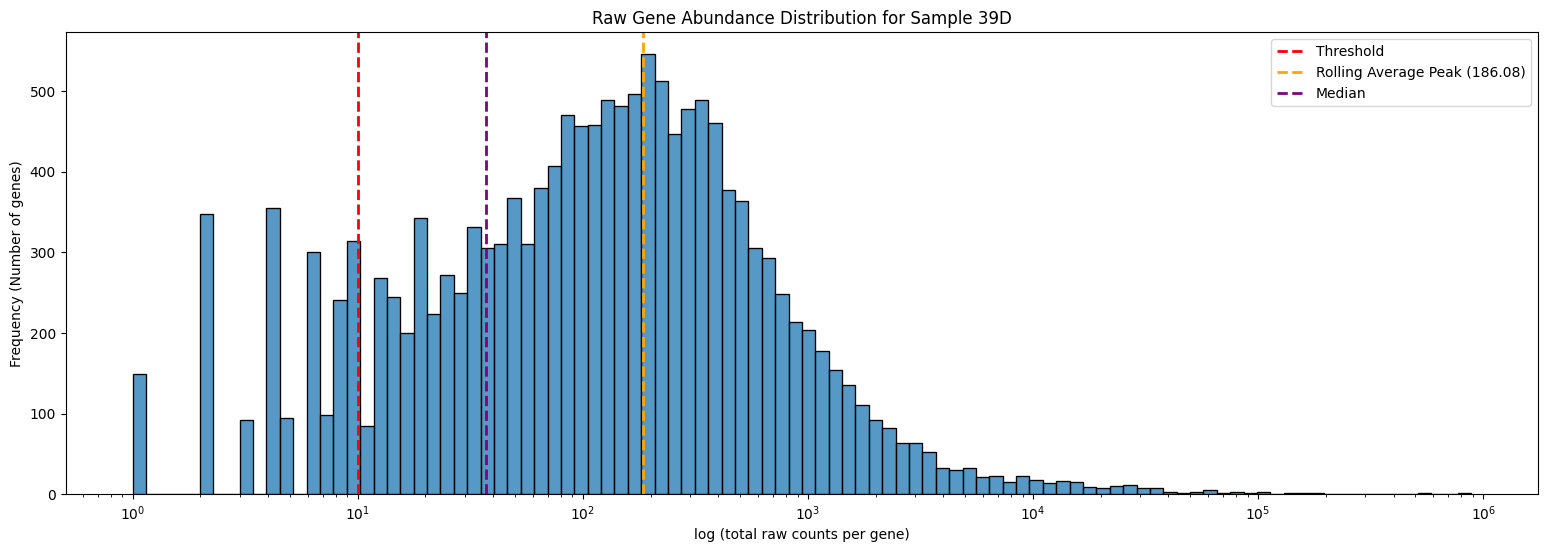

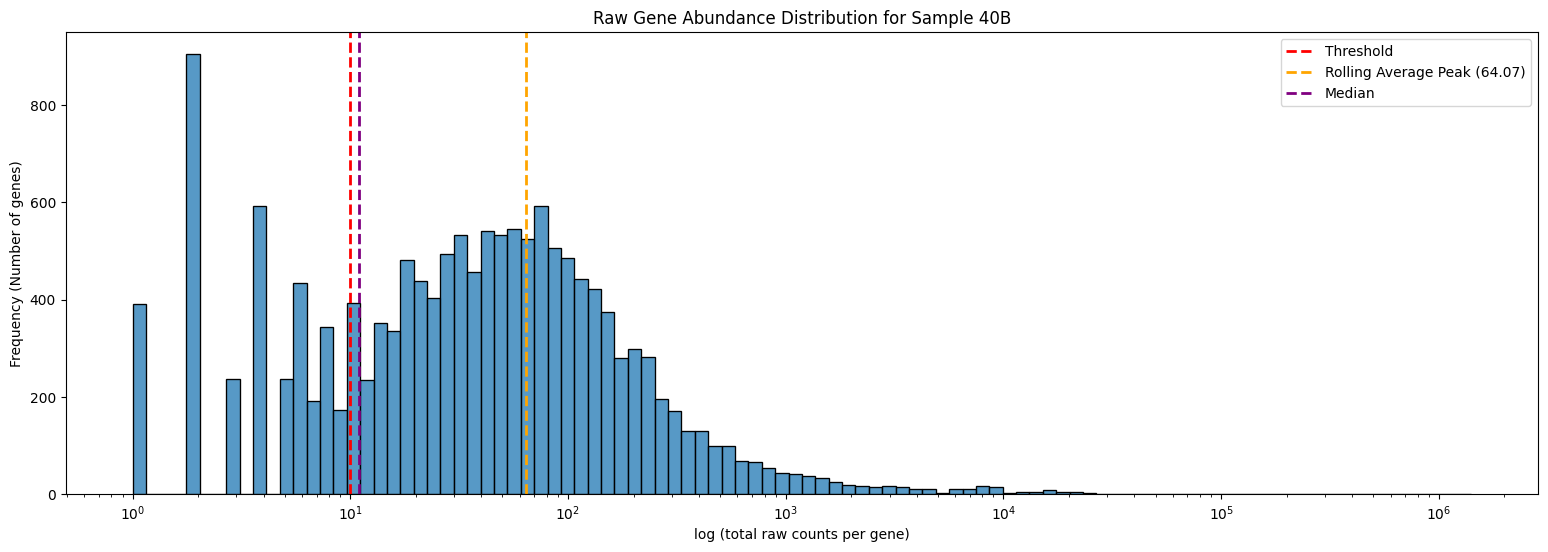

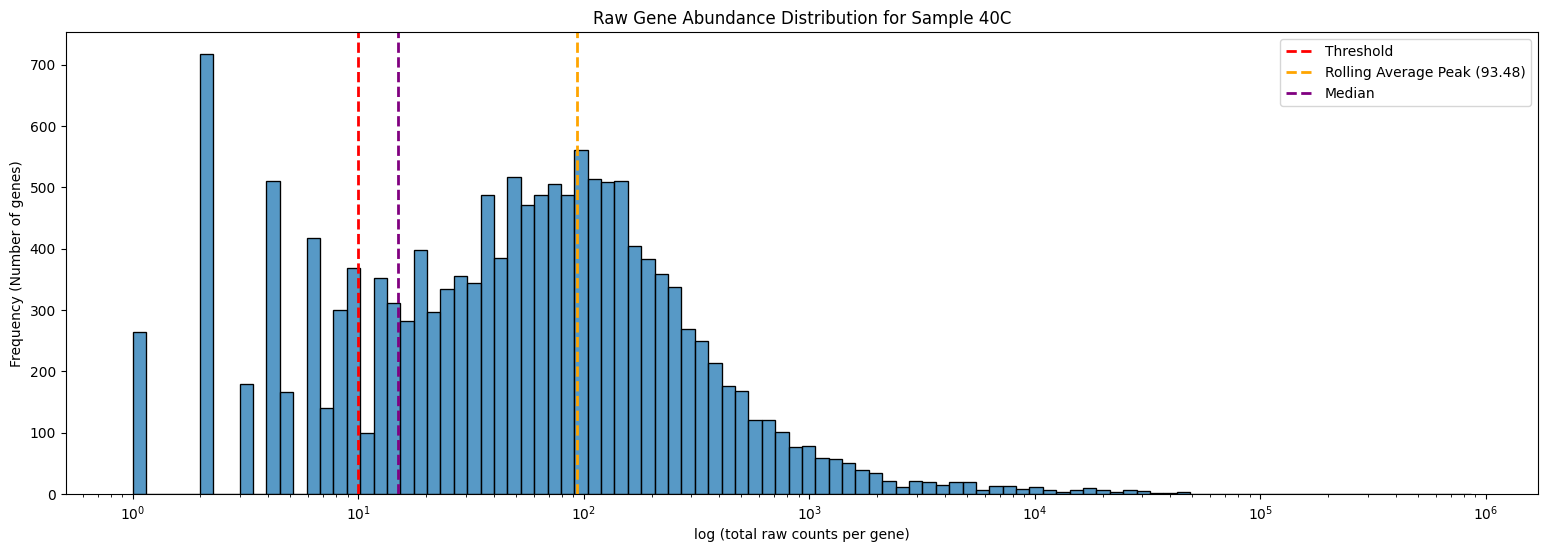

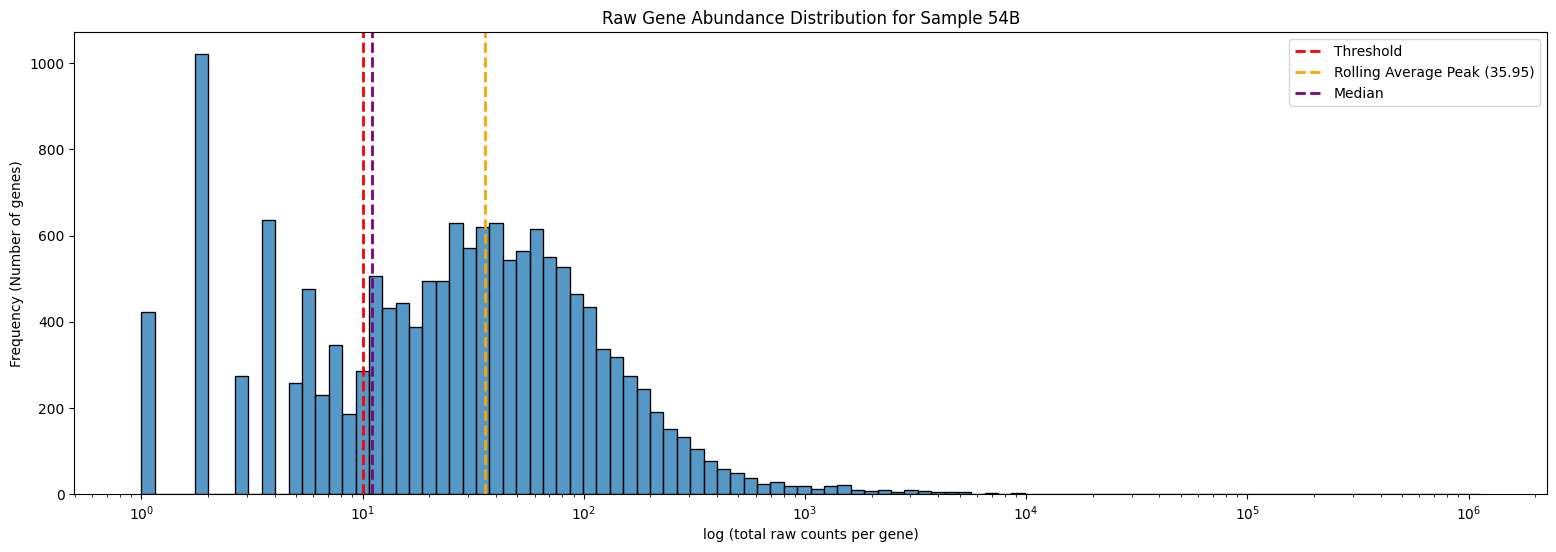

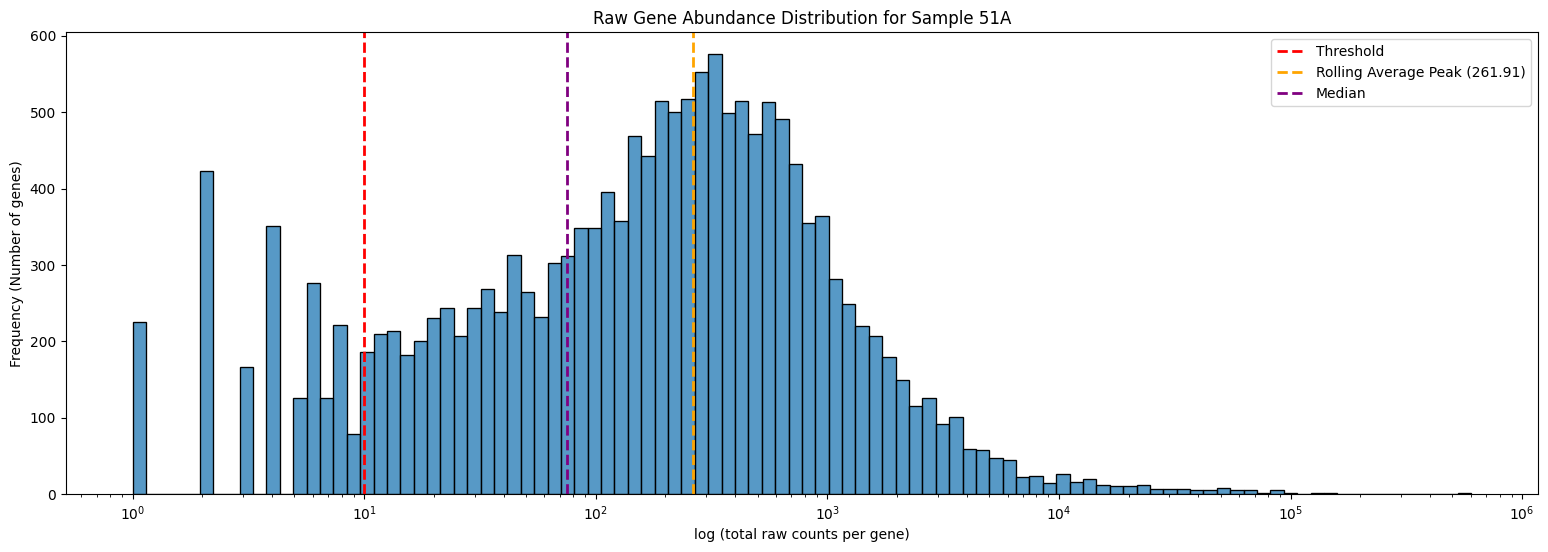

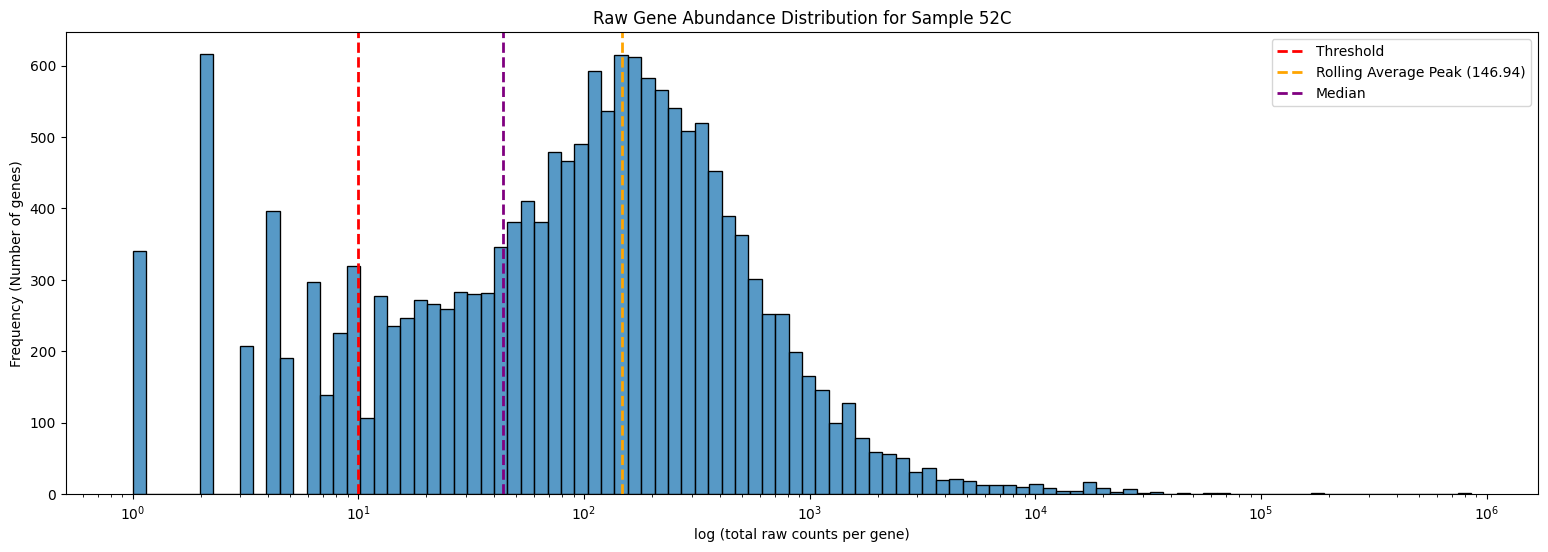

In [12]:
from data_normalization import gene_distribution
data = trans_raw_data
peaks = our_normalization_factors(data, nbins=150, window=7, show=False, single_figure=False)
#samples = trans_raw_data.columns
samples = ['39D','40B', '40C', '54B', '51A', '52C'] #problematic samples
for sample in  samples: 
    gene_distribution(data, sample,line_1=10, line_2=peaks[sample], line_3=data[sample].median(axis=0), label_1="Threshold", label_2= f"Rolling Average Peak ({peaks[sample]:.2f})", label_3= "Median") 


In [ ]:
import pandas as pd
from data_normalization import peaks_samplewise
count_data = pd.read_excel('Coffeeomics.xlsx', sheet_name='Trans_Counts', header=4, index_col=0)

#STRAT POINT: window = 5 bins = 150

peaks_samplewise (count_data, '54B', 150, 5)


In [ ]:
peaks = our_normalization (trans_raw_data, window=5)


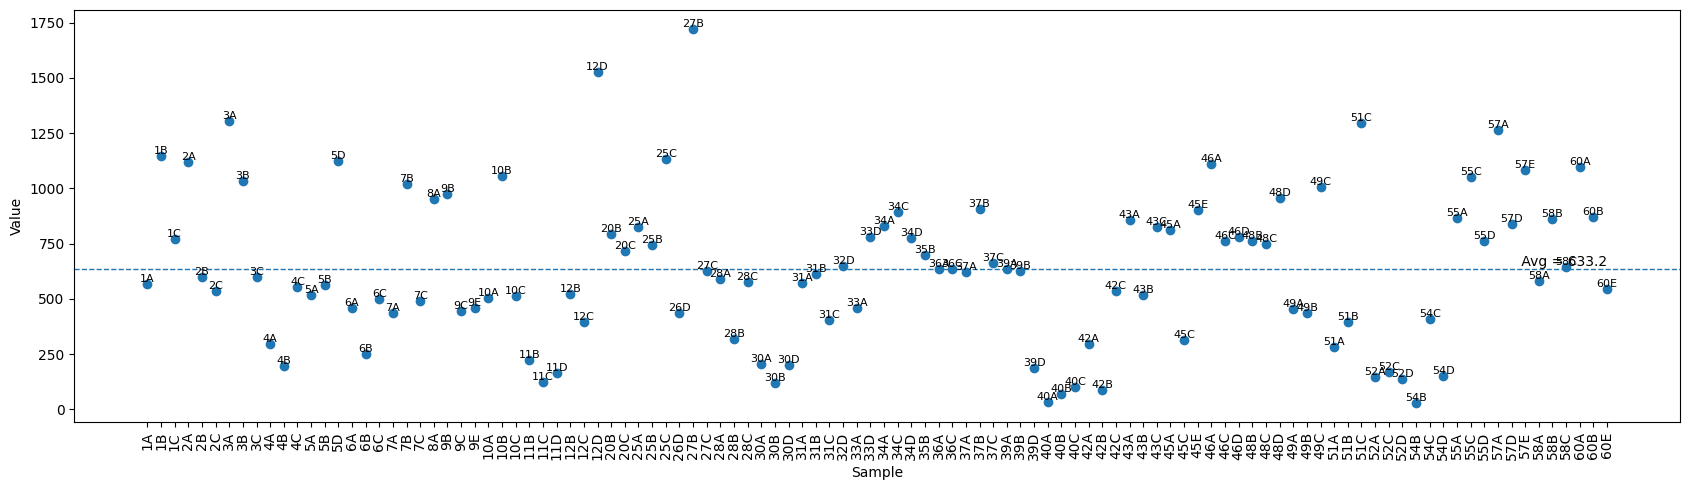

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def sort_key(k):
    num = int(''.join(filter(str.isdigit, k)))
    letter = ''.join(filter(str.isalpha, k))
    return (num, letter)


sorted_items = sorted(peaks.items(), key=lambda x: sort_key(x[0]))

labels = [k for k, v in sorted_items]
values = np.array([v for k, v in sorted_items])

x = np.arange(len(values))

# Compute average
avg = values.mean()

plt.figure(figsize=(17, 5))

# Scatter plot
plt.scatter(x, values)

# Average line
plt.axhline(avg, linestyle='--', linewidth=1)
plt.text(len(values)-1, avg, f' Avg = {avg:.1f}',
         va='bottom', ha='right')

# Add labels directly on points
for i, label in enumerate(labels):
    plt.text(x[i], values[i], label,
            fontsize=8,
            ha='center',
            va='bottom')

plt.xticks(x, labels, rotation=90)
plt.ylabel("Value")
plt.xlabel("Sample")
plt.tight_layout()
plt.show()
